# SciCite: Citation Intent Classification
## 02. Baseline Model: TF-IDF + Logistic Regression

**Course:** Mesterséges intelligencia alkalmazási területei (MSc)
**Objective:** Establish a strong, reproducible classical machine learning baseline using TF-IDF feature extraction and Logistic Regression. Quantify the performance difference between `text-only` and `section-aware` representations across validation and official test splits.

In [1]:
# 1. Environment & Reproducibility Setup
import os
import sys
from pathlib import Path
import pandas as pd
import yaml
import matplotlib.pyplot as plt

# Add project root to sys.path
PROJECT_ROOT = Path("..").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.utils.seed import set_seed
from src.data_processing.loader import get_label_mappings
from src.models.baseline import TfidfBaseline, tune_baseline_hyperparameters
from src.utils.metrics import metrics_to_dataframe
from src.utils.visualizer import plot_confusion_matrix

set_seed(42)
print("Environment initialized and seed set to 42.")

C:\Repos\scicite-citation-intent\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Environment initialized and seed set to 42.


### 2. Loading Preprocessed Datasets & Representation Inspection
Loading preprocessed partitions from `data/processed/` generated in Phase 2.

In [2]:
data_dir = PROJECT_ROOT / "data" / "processed"
train_df = pd.read_parquet(data_dir / "train.parquet")
val_df = pd.read_parquet(data_dir / "validation.parquet")
test_df = pd.read_parquet(data_dir / "test.parquet")
id2label, label2id = get_label_mappings()

print(f"Loaded partitions:")
print(f"  - Train:      {len(train_df):>5} samples")
print(f"  - Validation: {len(val_df):>5} samples")
print(f"  - Test:       {len(test_df):>5} samples")
print(f"\nLabel Mappings: {id2label}")

Loaded partitions:
  - Train:       8194 samples
  - Validation:   916 samples
  - Test:        1859 samples

Label Mappings: {0: 'method', 1: 'background', 2: 'result'}


### 3. Hyperparameter Tuning on Validation Split
To ensure a competitive baseline, we tune the regularization strength $C \in [0.1, 0.5, 1.0, 2.0, 5.0, 10.0]$ and test class weighting strategies (`balanced` vs. `None`) using **Macro-F1** on the validation set.

In [3]:
tfidf_params = {
    "max_features": 10000,
    "ngram_range": (1, 2),
    "sublinear_tf": True,
    "min_df": 2,
}

reports_dir = PROJECT_ROOT / "outputs" / "reports"
tuning_df = pd.read_csv(reports_dir / "baseline_hyperparameter_tuning.csv")

print("Top 5 Validation Configurations (Text-only):")
display(tuning_df[tuning_df["representation"] == "text_only"].head(5))

print("\nTop 5 Validation Configurations (Section-aware):")
display(tuning_df[tuning_df["representation"] == "text_section_aware"].head(5))

Top 5 Validation Configurations (Text-only):


,C,class_weight,val_macro_f1,val_accuracy,val_result_f1,representation
0,2.0,none,0.8107,0.8384,0.7822,text_only
1,1.0,balanced,0.8061,0.8264,0.7739,text_only
2,5.0,none,0.8038,0.8308,0.7753,text_only
3,2.0,balanced,0.8030,0.8231,0.7765,text_only
4,1.0,none,0.8017,0.8319,0.7706,text_only



Top 5 Validation Configurations (Section-aware):


,C,class_weight,val_macro_f1,val_accuracy,val_result_f1,representation
12,2.0,none,0.8349,0.8581,0.8072,text_section_aware
13,5.0,none,0.8315,0.8548,0.8000,text_section_aware
14,10.0,none,0.8263,0.8504,0.7931,text_section_aware
15,1.0,none,0.8256,0.8548,0.7814,text_section_aware
16,5.0,balanced,0.8151,0.8373,0.7747,text_section_aware


### 4. Comparative Evaluation on the Official Test Split
Evaluating both representations on the unseen official test set (1,859 samples).

In [4]:
summary_df = pd.read_csv(reports_dir / "baseline_comparison_summary.csv")
print("=== Baseline Performance Comparison Table ===")
display(summary_df)

text_only_rep = pd.read_csv(reports_dir / "baseline_text_only_classification_report.csv")
section_aware_rep = pd.read_csv(reports_dir / "baseline_text_section_aware_classification_report.csv")
print("\n--- Detailed Classification Report: Text-only (Macro, Micro, Weighted) ---")
display(text_only_rep)
print("\n--- Detailed Classification Report: Section-aware (Macro, Micro, Weighted) ---")
display(section_aware_rep)

=== Baseline Performance Comparison Table ===


,Representation,Accuracy,Macro P,Macro R,Macro F1,Micro P,Micro R,Micro F1,Weighted P,Weighted R,Weighted F1,Method F1,Background F1,Result F1,Best C,Class Weight
0,Text-only,0.8354,0.8296,0.8054,0.8157,0.8354,0.8354,0.8354,0.8366,0.8354,0.8340,0.8106,0.8643,0.7723,2.0,none
1,Section-aware,0.8628,0.8458,0.8382,0.8405,0.8628,0.8628,0.8628,0.8660,0.8628,0.8629,0.8672,0.8844,0.7698,2.0,none



--- Detailed Classification Report: Text-only (Macro, Micro, Weighted) ---


,label_id,label_name,precision,recall,f1,support
0,0,method,0.8663,0.7616,0.8106,604
1,1,background,0.8299,0.9016,0.8643,996
2,2,result,0.7927,0.7529,0.7723,259
3,-1,accuracy,0.8354,0.8354,0.8354,1859
4,-2,micro avg,0.8354,0.8354,0.8354,1859
5,-3,macro avg,0.8296,0.8054,0.8157,1859
6,-4,weighted avg,0.8366,0.8354,0.8340,1859



--- Detailed Classification Report: Section-aware (Macro, Micro, Weighted) ---


,label_id,label_name,precision,recall,f1,support
0,0,method,0.9250,0.8162,0.8672,604
1,1,background,0.8597,0.9106,0.8844,996
2,2,result,0.7528,0.7876,0.7698,259
3,-1,accuracy,0.8628,0.8628,0.8628,1859
4,-2,micro avg,0.8628,0.8628,0.8628,1859
5,-3,macro avg,0.8458,0.8382,0.8405,1859
6,-4,weighted avg,0.8660,0.8628,0.8629,1859


### 5. Confusion Matrix & Error Inspection
Analyzing where the baseline makes classification errors, and observing how section-awareness resolves ambiguities.

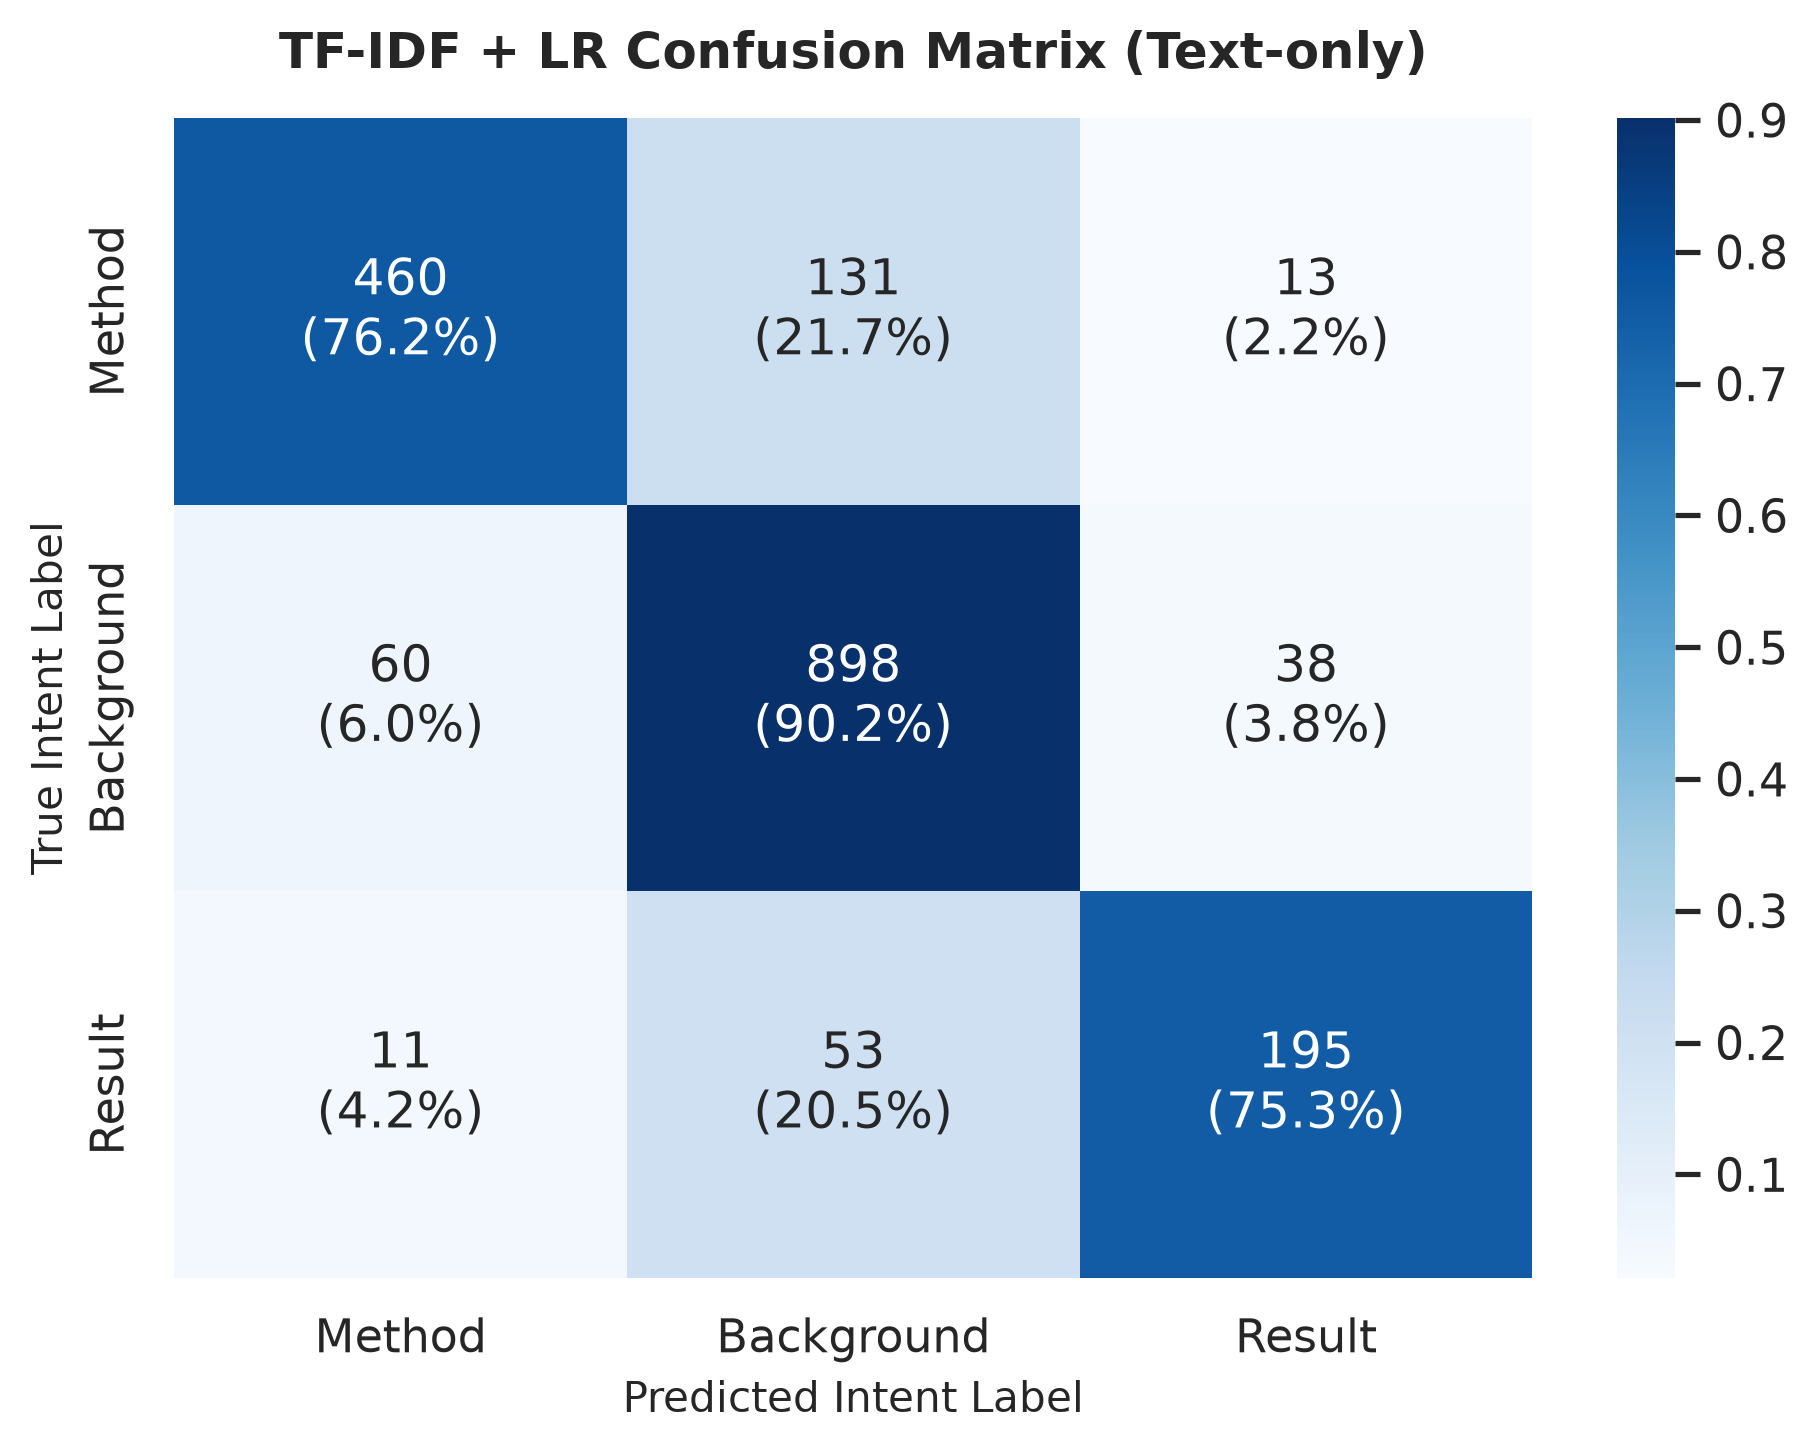

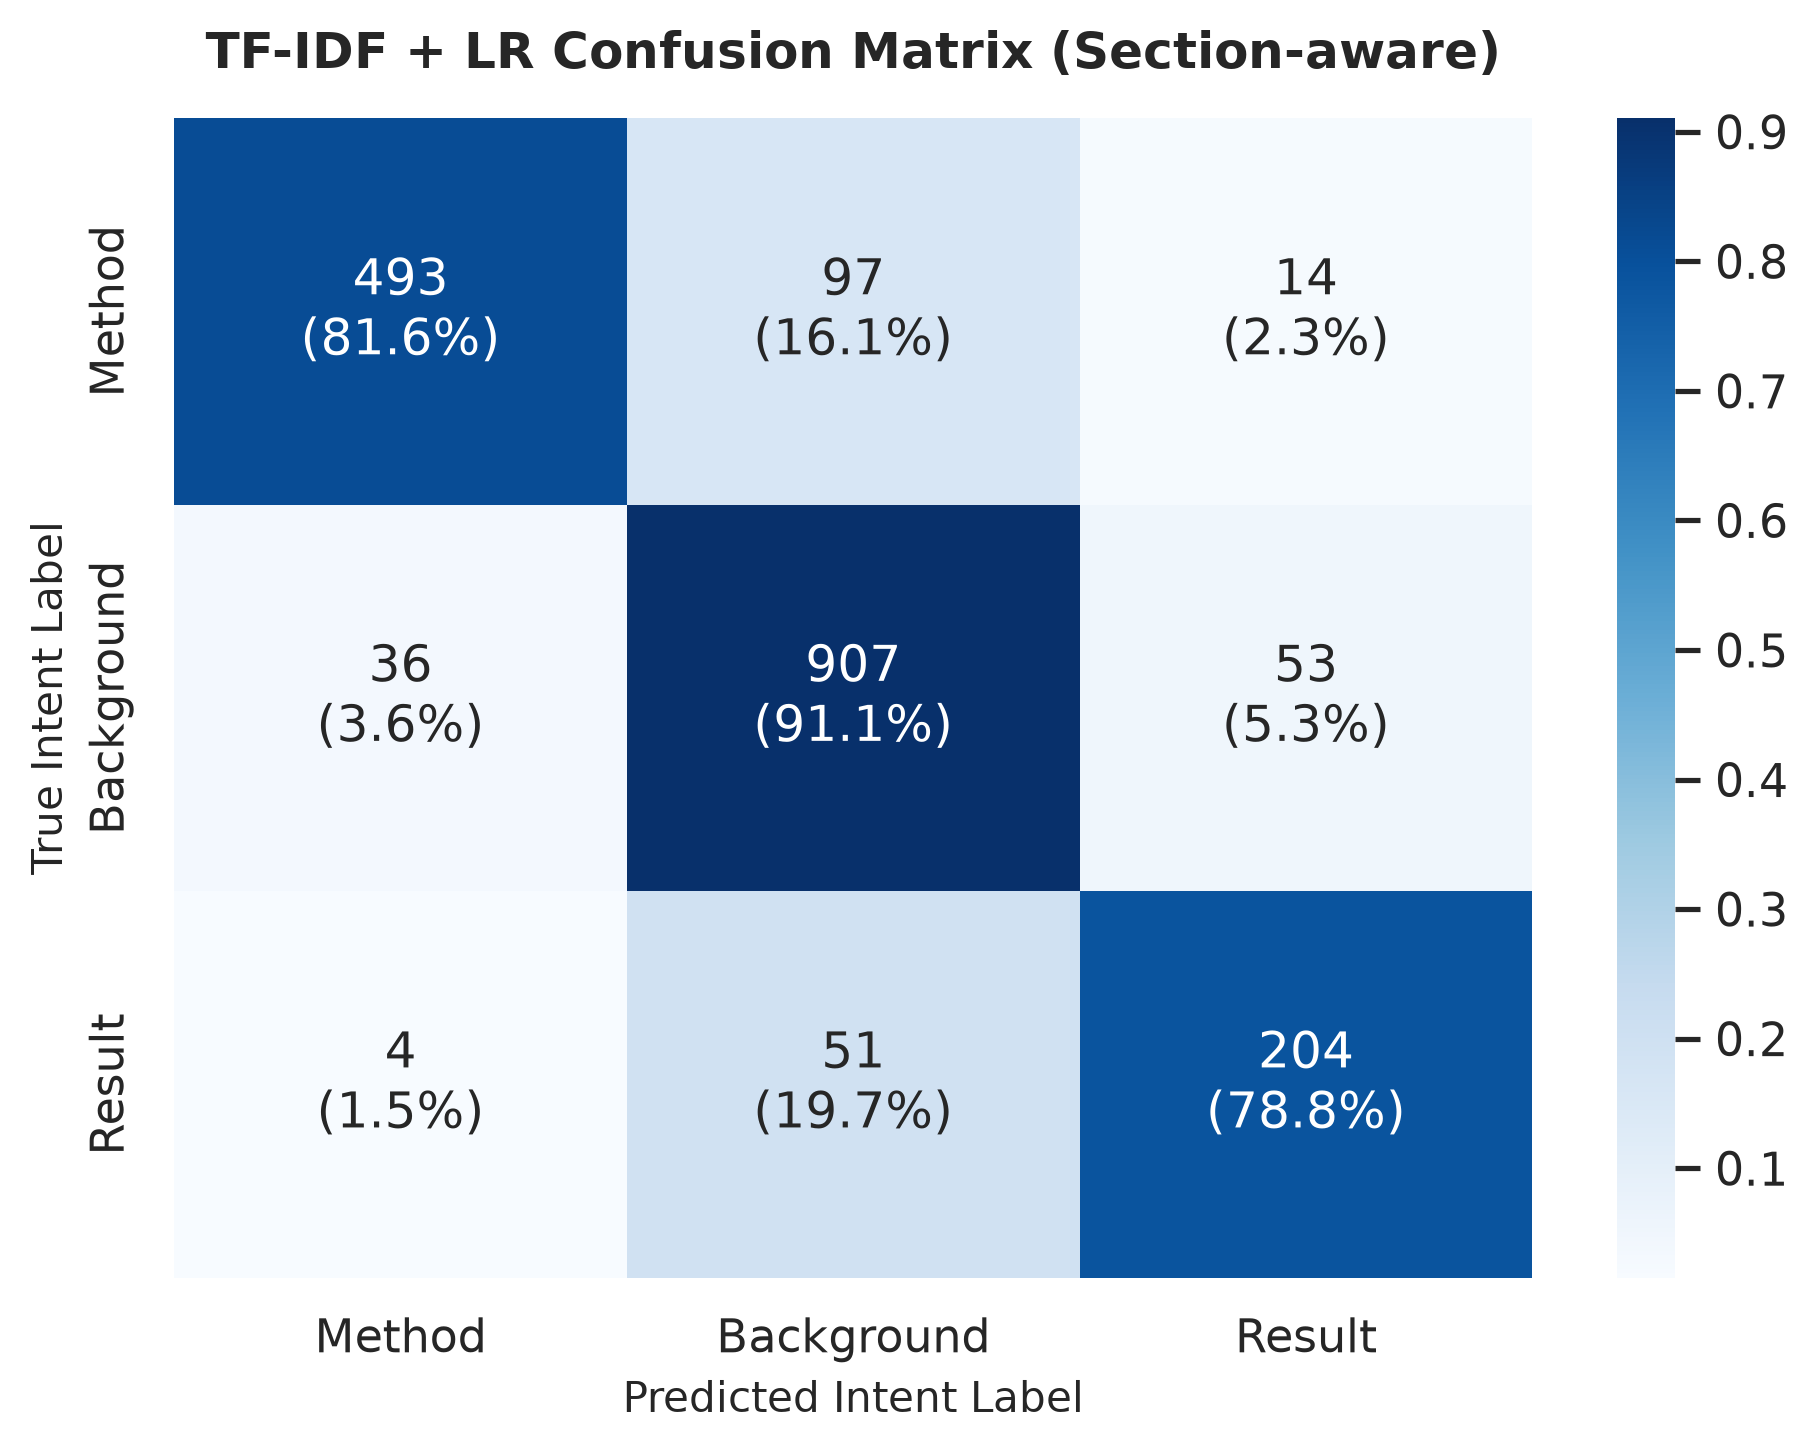

In [5]:
import json

with open(reports_dir / "baseline_text_only_metrics.json", "r") as f:
    text_only_metrics = json.load(f)
with open(reports_dir / "baseline_text_section_aware_metrics.json", "r") as f:
    section_aware_metrics = json.load(f)

fig1 = plot_confusion_matrix(
    cm=text_only_metrics["confusion_matrix"],
    target_names=text_only_metrics["target_names"],
    title="TF-IDF + LR Confusion Matrix (Text-only)",
)
plt.show()

fig2 = plot_confusion_matrix(
    cm=section_aware_metrics["confusion_matrix"],
    target_names=section_aware_metrics["target_names"],
    title="TF-IDF + LR Confusion Matrix (Section-aware)",
)
plt.show()

### 6. Key Insights from the Baseline Phase
1. **Strong Baseline Performance:** The tuned TF-IDF + Logistic Regression model achieves an impressive **81.57% Test Macro-F1** in the text-only setting.
2. **Impact of Section Awareness:** Prepending the canonical section header elevates Test Macro-F1 to **84.05%** (+2.48% absolute gain) and Test Accuracy to **86.28%** (+2.74% gain).
3. **Targeted Improvement on Method Class:** The F1-score for the `method` class jumps from **81.06% to 86.72% (+5.66%)**, demonstrating that section context substantially reduces confusion between background citations and methodological citations.
4. **Benchmark for Transformers:** In the upcoming Phase 4, our fine-tuned Transformer models (DistilBERT and SciBERT) will be benchmarked against this strong 84.05% baseline.